# Модель анализа тональности текста

Заказчик:
- картографический сервис YouMap

Бизнес постановка:
- Команде качества нужно научиться автоматически находить негативные сообщения и передавать их на приоритетную обработку. Необходимо разработать инструмент для автоматизированного выявления негативных отзывов.

Датасет:

|Признак|Описание|Комментарий|
|:---|:---|:---|
|text|Текст отзыва|Отзывы для обучения нейросети|
|address|Адрес организации|Только для EDA|
|federal_district|Федеральный округ|Категориальный признак|
|name_ru|Название организации|Только для EDA.|
|rubrics|Категории, к которым относится организация|Только для EDA|
|rubrics_count|Количество категорий, к которым относится организация|Числовой признак|
|review_len_chars|Длина отзыва в символах|Числовой признак|
|review_len_words|Длина отзыва в словах|Числовой признак|
|emoji_count|Количество эмодзи в отзыве|Числовой признак|
|target|1 — негативный отзыв, оценка 1–2. <br> 0 — остальные отзывы, оценка 3–5.|Целевая переменная|


Основная метрика — PR-AUC, вспомогательные — ROC-AUC, precision, recall, F1-мера.


## 1. Импорт библиотек, настройка констант, обеспечение воспроизводимости

In [1]:
from pathlib import Path
from collections import Counter
import random
import re
import string

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_fscore_support,
    roc_auc_score
)

from IPython.display import display

In [2]:
RANDOM_STATE = 42
DATA_PATH = "https://code.s3.yandex.net/datasets/ds_s26_geo_reviews"
MODELS_DIR = Path("models")
MODELS_DIR.mkdir(exist_ok=True)


def set_seed(seed: int = RANDOM_STATE) -> None:
    # Фиксация random seed для random, numpy и torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(RANDOM_STATE)

# Определение устройства
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

## 2. Загрузка данных и исследовательский анализ

In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Размер датасета: 11796 строк, 10 столбцов


,text,address,federal_district,name_ru,rubrics,rubrics_count,review_len_chars,review_len_words,emoji_count,target
0,Бронировала квартиру в Тюмени. Бронирование пр...,"Челябинск, проспект Ленина, 21В",Уральский ФО,Квартирка,Информационный интернет-сайт;Агентство недвижи...,2,121,14,0,0
1,Праздновали Новый год в этом отеле.\nСамое пот...,"Иркутский район, Листвянское муниципальное обр...",Сибирский ФО,Байкал Хан,Гостиница,1,577,89,0,0
2,"Очень нравится грумер Анна, всегда приветливая...","Московская область, Королёв, Подмосковная улиц...",Центральный ФО,Счастливые хвостатые,"Зоосалон, зоопарикмахерская;Зоомагазин",3,434,67,0,0
3,В городе Салават директора на месте невозможно...,"Республика Башкортостан, Салават, улица Ленина...",Приволжский ФО,Спортмастер,Спортивный магазин;Спортивная одежда и обувь;Т...,3,201,32,0,1
4,Огромное спасибо за заказ.\nЗаказ очень хорошо...,"Москва, Троицкая улица, 7/1с1",Центральный ФО,Дом Чая,Магазин чая;Магазин посуды,2,183,27,0,0


In [4]:
def show_df_info(df: pd.DataFrame):
    """Типы данных, пропуски и количество уникальных значений"""
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing part, %": df.isna().sum() / len(df) * 100,
        "unique": df.nunique(),
    }))

In [5]:
show_df_info(df=df)

,dtype,missing,"missing part, %",unique
text,object,0,0.000000,11796
address,object,0,0.000000,10614
federal_district,object,0,0.000000,8
name_ru,object,25,0.211936,9012
rubrics,object,0,0.000000,3287
rubrics_count,int64,0,0.000000,9
review_len_chars,int64,0,0.000000,1193
review_len_words,int64,0,0.000000,302
emoji_count,int64,0,0.000000,22
target,int64,0,0.000000,2


,target,count,share
0,0,10723,0.909037
1,1,1073,0.090963


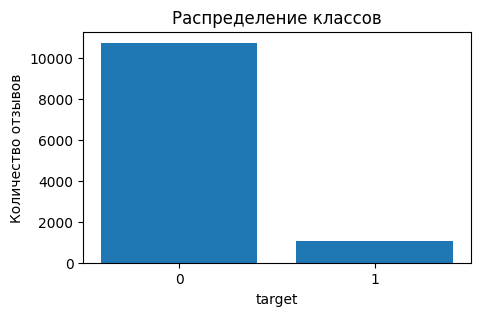

In [6]:
# Распределение классов: количество объектов каждого класса и их доля
target_distribution = (
    df["target"]
    .value_counts()
    .sort_index()
    .rename_axis("target")
    .reset_index(name="count")
)
target_distribution["share"] = target_distribution["count"] / len(df)

display(target_distribution)

plt.figure(figsize=(5, 3))
plt.bar(target_distribution["target"].astype(str), target_distribution["count"])
plt.title("Распределение классов")
plt.xlabel("target")
plt.ylabel("Количество отзывов")
plt.show()

In [7]:
pd.set_option("display.max_colwidth", 220)

# Примеры объектов каждого класса
for class_value, title in [(0, "ненегативные отзывы"), (1, "негативные отзывы")]:
    print(f"Примеры: {title}")
    examples = (
        df[df["target"] == class_value]
        [["text", "federal_district", "rubrics_count", "review_len_words", "emoji_count", "target"]]
        .sample(3, random_state=RANDOM_STATE)
    )
    display(examples)

Примеры: ненегативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
1809,"Спасибо, Дмитрию за грамотный подбор экипировки для детей",Центральный ФО,3,8,0,0
3561,"Мне очень понравилось! Зашла туда случайно, хотелось выпить кофе с чем-нибудь вкусненьким.. Официантка очень приветливая и обходительная, предложила выбрать место, в зале очень уютно. Попробовала тосты с авокадо и Бо...",Центральный ФО,1,43,0,0
10301,"Всё просто супер! В номере есть всё необходимое, для автономного проживания. Особенно радует небольшая кухня с посудой, столовыми приборами, микроволновкой, электрочайником и плитой. А прямо под окнами есть супермарк...",Сибирский ФО,1,116,0,0


Примеры: негативные отзывы


,text,federal_district,rubrics_count,review_len_words,emoji_count,target
10728,"Совершенно отвратительное поведение дирекции: нужно было проехать по дороге (городская территория, как и весь МУП Рынок) - разгрузиться у соседнего здания. Как оказалось, въезд/проезд/пролёт на ранок стоит 800 рублей...",Центральный ФО,1,52,0,1
8118,"Купил велик ребёнку, он сломался через 3 недели эксплуатации, приехали в сервис, но тут его не приняли, записать могут через неделю не раньше, на просьбу уделить 2 минуты и оценить масштаб ремонта тоже отказали, хо...",Центральный ФО,2,88,0,1
11716,Ни в коем случае не посещайте данную мойку!\nПродолжают списывать деньги с карты после единоразового посещения!!!\nСписывают без моего ведома!,Центральный ФО,2,20,0,1


### Выводы

- для таргета наблюдается дисбаланс классов: количество негативных отзывов в разы меньше, нежели ненегативных
- `accuracy` может вводить в заблуждение: константная модель предсказания только преобладающего класса `target = 0 ` уже даст достаточно высокую метрику `accuracy`. 
- явные пропуски обнаружены в `name_ru` — названия организаций. Доля пропусков составляет около 0,2 %. Ввиду малого количества пропусков строки с ними можно удалить
- могут присутствовать искажения и шум в таргете. Более того, есть еще промежуточная оценка 3 балла - по сути отзыв при такой оценке может быть как негативный, так и умеренно позитивный. Текущая разметка эту разницу не чувствует 

In [8]:
old_df_len = len(df)
df = df.dropna(subset=['name_ru'])
show_df_info(df=df)

print('Потери при очистке составили (%): ', (old_df_len - len(df)) / old_df_len * 100)

,dtype,missing,"missing part, %",unique
text,object,0,0.0,11771
address,object,0,0.0,10592
federal_district,object,0,0.0,8
name_ru,object,0,0.0,9012
rubrics,object,0,0.0,3282
rubrics_count,int64,0,0.0,9
review_len_chars,int64,0,0.0,1192
review_len_words,int64,0,0.0,302
emoji_count,int64,0,0.0,22
target,int64,0,0.0,2


Потери при очистке составили (%):  0.2119362495761275


## 3. Подготовка числовых признаков

Генерация числовых показателей:

- `punct_count` — количество знаков препинания.
- `question_count` — количество вопросительных знаков.
- `exclamation_count` — количество восклицательных знаков.
- `newline_count` — количество переносов строк.
- `digit_count` — количество цифр.
- `uppercase_share` — доля заглавных букв среди всех букв.
- `avg_word_len` — средняя длина слова.

In [10]:
df_features = df.copy()
text = df_features["text"].astype(str)
punctuation = f'[{re.escape(string.punctuation + "«»—–…“”„")}]'


# 1. Количество знаков препинания
df_features["punct_count"] = text.str.count(punctuation)

# 2. Количество вопросительных знаков
df_features["question_count"] = text.str.count(r'\?')

# 3. Количество восклицательных знаков
df_features["exclamation_count"] = text.str.count(r'\!')

# 4. Количество переносов строк
df_features["newline_count"] = text.str.count(r"\\n") + text.str.count("\n")

# 5. Количество цифр
df_features["digit_count"] = text.str.count(r'\d')

# 6. Доля заглавных букв среди всех букв
# Сначала посчитайте общее число букв и число заглавных букв
letters_count = text.str.count(r'[A-Za-zА-Яа-яЁё]')
upper_count = text.str.count(r'[A-ZА-ЯЁ]')
df_features["uppercase_share"] = upper_count.astype(np.float64) / letters_count.replace(0, np.nan)  # обработка деления на 0
df_features["uppercase_share"] = df_features["uppercase_share"].fillna(0)

# 7. Средняя длина слова
df_features["avg_word_len"] = (
    text
    .str
    .findall(r'\b\w+\b')
    .apply(
        lambda words: np.mean([len(w) for w in words]) if words else np.nan
    )
)
df_features["avg_word_len"] = df_features["avg_word_len"].fillna(0)

numeric_features = [
    "rubrics_count",
    "emoji_count",
    "punct_count",
    "question_count",
    "exclamation_count",
    "newline_count",
    "digit_count",
    "uppercase_share",
    "avg_word_len",
]

categorical_features = ["federal_district"]

display(df_features[numeric_features + ["target"]].describe().T)

district_distribution = (
    df_features["federal_district"]
    .value_counts()
    .rename_axis("federal_district")
    .reset_index(name="count")
)
district_distribution["share"] = district_distribution["count"] / len(df_features)
display(district_distribution)

,count,mean,std,min,25%,50%,75%,max
rubrics_count,11771.0,1.982839,1.095156,1.000000,1.000000,2.000000,3.000000,10.00
emoji_count,11771.0,0.320449,2.010450,0.000000,0.000000,0.000000,0.000000,173.00
punct_count,11771.0,12.089032,12.664854,0.000000,5.000000,8.000000,14.000000,186.00
question_count,11771.0,0.054371,0.393792,0.000000,0.000000,0.000000,0.000000,10.00
exclamation_count,11771.0,1.123354,2.347198,0.000000,0.000000,0.000000,1.000000,35.00
newline_count,11771.0,0.770878,2.179090,0.000000,0.000000,0.000000,0.000000,34.00
digit_count,11771.0,1.143318,3.273737,0.000000,0.000000,0.000000,1.000000,92.00
uppercase_share,11771.0,0.027948,0.016287,0.000000,0.017857,0.025362,0.034602,0.34
avg_word_len,11771.0,5.823240,0.771549,2.833333,5.285714,5.736842,6.266667,13.00
target,11771.0,0.091071,0.287723,0.000000,0.000000,0.000000,0.000000,1.00


,federal_district,count,share
0,Центральный ФО,4915,0.417552
1,Северо-Западный ФО,1917,0.162858
2,Южный ФО,1760,0.149520
3,Приволжский ФО,1544,0.131170
4,Сибирский ФО,588,0.049953
5,Уральский ФО,518,0.044006
6,Северо-Кавказский ФО,363,0.030839
7,Дальневосточный ФО,166,0.014102


In [12]:
# обучающая, валидационная и тестовая выборки в пропорции 70:15:15
# + стратификация
train_df, temp_df = train_test_split(
    df_features,
    test_size=0.3,
    stratify=df_features['target'],
    random_state=RANDOM_STATE,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['target'],
    random_state=RANDOM_STATE,
)

split_stats = pd.DataFrame(
    {
        "rows": [len(train_df), len(val_df), len(test_df)],
        "target_share": [
            train_df["target"].mean(),
            val_df["target"].mean(),
            test_df["target"].mean(),
        ],
    },
    index=["обучающая", "валидационная", "тестовая"],
)

display(split_stats)

,rows,target_share
обучающая,8239,0.091030
валидационная,1766,0.091166
тестовая,1766,0.091166


In [13]:
df_features.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11771 entries, 0 to 11795
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   text               11771 non-null  object 
 1   address            11771 non-null  object 
 2   federal_district   11771 non-null  object 
 3   name_ru            11771 non-null  object 
 4   rubrics            11771 non-null  object 
 5   rubrics_count      11771 non-null  int64  
 6   review_len_chars   11771 non-null  int64  
 7   review_len_words   11771 non-null  int64  
 8   emoji_count        11771 non-null  int64  
 9   target             11771 non-null  int64  
 10  punct_count        11771 non-null  int64  
 11  question_count     11771 non-null  int64  
 12  exclamation_count  11771 non-null  int64  
 13  newline_count      11771 non-null  int64  
 14  digit_count        11771 non-null  int64  
 15  uppercase_share    11771 non-null  float64
 16  avg_word_len       11771 no

In [14]:
# scaler для числовых признаков и encoder для federal_district
scaler = StandardScaler()

one_hot_encoder = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)


# Важно: fit только на обучающей выборке, для валидационной и тестовой используйте transform
X_train_num = scaler.fit_transform(train_df[numeric_features])
X_val_num = scaler.transform(val_df[numeric_features])
X_test_num = scaler.transform(test_df[numeric_features])

X_train_cat = one_hot_encoder.fit_transform(train_df[categorical_features])
X_val_cat = one_hot_encoder.transform(val_df[categorical_features])
X_test_cat = one_hot_encoder.transform(test_df[categorical_features])

X_train = np.hstack([X_train_num, X_train_cat]).astype("float32")
X_val = np.hstack([X_val_num, X_val_cat]).astype("float32")
X_test = np.hstack([X_test_num, X_test_cat]).astype("float32")

y_train = train_df["target"].values.astype("float32")
y_val = val_df["target"].values.astype("float32")
y_test = test_df["target"].values.astype("float32")

feature_names = numeric_features + list(
    one_hot_encoder.get_feature_names_out(categorical_features)
)

print("X_train:", X_train.shape, "X_val:", X_val.shape, "X_test:", X_test.shape)
print("Количество признаков после кодирования:", len(feature_names))
display(pd.DataFrame({"feature": feature_names}))

X_train: (8239, 16) X_val: (1766, 16) X_test: (1766, 16)
Количество признаков после кодирования: 16


,feature
0,rubrics_count
1,emoji_count
2,punct_count
3,question_count
4,exclamation_count
5,newline_count
6,digit_count
7,uppercase_share
8,avg_word_len
9,federal_district_Приволжский ФО


In [15]:
# Создание Dataset и DataLoader

class ReviewsDataset(Dataset):
    def __init__(self, features: np.ndarray, target: np.ndarray):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.target = torch.tensor(target, dtype=torch.float32)

    def __len__(self):
        # Верните количество объектов в датасете
        return len(self.target)

    def __getitem__(self, idx):
        # Верните пару: признаки объекта и целевую метку
        return self.features[idx], self.target[idx]


BATCH_SIZE = 128

numeric_loaders = {
    "train": DataLoader(
        ReviewsDataset(features=X_train, target=y_train),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsDataset(features=X_val, target=y_val),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsDataset(features=X_test, target=y_test),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

features_batch, target_batch = next(iter(numeric_loaders["train"]))
print("features_batch:", features_batch.shape, features_batch.dtype)
print("target_batch:", target_batch.shape, target_batch.dtype)

features_batch: torch.Size([128, 16]) torch.float32
target_batch: torch.Size([128]) torch.float32


## 4. Эксперимент 1 — MLP на числовых признаках

In [16]:
def calc_metrics(y_true: np.ndarray, y_prob: np.ndarray, threshold: float = 0.5) -> dict:
    # PR-AUC и ROC-AUC по вероятностям y_prob
    # Для precision, recall, F1 и accuracy - вероятности в классы
    y_pred = np.where(y_prob > threshold, 1, 0)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="binary",
        zero_division=0,
    )

    return {
        "pr_auc": average_precision_score(y_true, y_prob),
        "roc_auc": roc_auc_score(y_true, y_prob),
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy_score(y_true, y_pred),
    }


majority_accuracy = (test_df["target"] == 0).mean()
print(f"Accuracy константной модели, которая всегда предсказывает 0: {majority_accuracy:.3f}")

Accuracy константной модели, которая всегда предсказывает 0: 0.909


In [17]:
# Класс модели и обучение
class MLP(nn.Module):
    def __init__(self, input_dim: int, hidden_layers=(32, 16), dropout: float = 0.0):
        super().__init__()
        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_layers:
            layers.append(nn.Linear(prev_dim, hidden_dim))
            layers.append(nn.ReLU())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x) -> torch.Tensor:
        # Опишите прямой проход модели
        return self.net(x)

In [18]:
def train_epoch(model, loader, criterion, optimizer, device):
    """Эпоха обучения модели
    
    Args:
        model: модель для обучения
        loader: загрузчик данных
        criterion: вычислитель ошибки (loss-а)
        optimizer: оптимизатор
        device: устройство, на котором будут проводиться расчёты
    """
    model.train()
    total_loss = 0

    for features, target in loader:
        features = features.to(device)
        target = target.to(device)

        # Выполните шаг обучения:
        # zero_grad → forward → loss → backward → step
        optimizer.zero_grad()
        logits = model(features).squeeze(-1) # лишняя размерность
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(target)

    return total_loss / len(loader.dataset)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0
    all_probs = []
    all_targets = []

    with torch.no_grad():
        for features, target in loader:
            features = features.to(device)
            target = target.to(device)

            # Выполните forward pass и посчитайте loss
            logits = model(features).squeeze(-1)
            loss = criterion(logits, target)
            probs = torch.sigmoid(logits)

            total_loss += loss.item() * len(target)
            all_probs.extend(probs.cpu().numpy())
            all_targets.extend(target.cpu().numpy())

    y_true = np.array(all_targets)
    y_prob = np.array(all_probs)
    metrics = calc_metrics(y_true, y_prob)
    metrics["loss"] = total_loss / len(loader.dataset)

    return metrics, y_true, y_prob

In [19]:
pos_weight_value = (y_train == 0).sum() / (y_train == 1).sum()
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"pos_weight: {pos_weight_value:.2f}")


def run_experiment(model, loaders: dict, config: dict):
    """Эксперимент: обучение на train и оценка модели на validate"""
    model = model.to(device)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config["lr"],
        weight_decay=config["weight_decay"],
    )

    history = []
    best_state = None
    best_val_pr_auc = -np.inf

    for epoch in range(1, config["epochs"] + 1):
        train_loss = train_epoch(model, loaders["train"], criterion, optimizer, device)
        val_metrics, _, _ = evaluate(model, loaders["val"], criterion, device)

        history.append(
            {
                "epoch": epoch,
                "train_loss": train_loss,
                **val_metrics,
            }
        )

        if val_metrics["pr_auc"] > best_val_pr_auc:
            best_val_pr_auc = val_metrics["pr_auc"]
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

pos_weight: 9.99


In [20]:
mlp_configs = [
    {
        "name": "small_no_reg",
        "hidden_layers": (16,),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "deep_no_reg",
        "hidden_layers": (64, 32),
        "dropout": 0.0,
        "lr": 0.001,
        "weight_decay": 0.0,
        "epochs": 8,
    },
    {
        "name": "regularized",
        "hidden_layers": (64, 32),
        "dropout": 0.3,
        "lr": 0.001,
        "weight_decay": 0.0001,
        "epochs": 8,
    },
]

In [21]:
mlp_histories = {}
mlp_models = {}
mlp_rows = []

for config in mlp_configs:
    set_seed(RANDOM_STATE)

    model = MLP(
        input_dim=X_train.shape[1],
        hidden_layers=config["hidden_layers"],
        dropout=config["dropout"],
    )
    model, history = run_experiment(model, numeric_loaders, config)

    # Посчитайте метрики на test
    test_metrics, _, _ = evaluate(model=model, loader=numeric_loaders['test'], criterion=criterion, device=device)

    mlp_rows.append(
        {
            "name": config["name"],
            "best_val_pr_auc": history["pr_auc"].max(),
            **test_metrics,
        }
    )
    mlp_histories[config["name"]] = history
    mlp_models[config["name"]] = model

mlp_results = (
    pd.DataFrame(mlp_rows)
    .sort_values("best_val_pr_auc", ascending=False)
    .reset_index(drop=True)
)

display(mlp_results.round(4))

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,deep_no_reg,0.3889,0.3819,0.8095,0.2659,0.6770,0.3818,0.8001,0.9725
1,small_no_reg,0.3855,0.3804,0.8016,0.2380,0.7081,0.3562,0.7667,0.9958
2,regularized,0.3740,0.3772,0.8042,0.2483,0.6832,0.3642,0.7826,0.9806


In [22]:
best_mlp_name = mlp_results.iloc[0]["name"]
best_mlp_model = mlp_models[best_mlp_name]

best_mlp_path = MODELS_DIR / "best_mlp_numeric.pt"

# Сохраните веса лучшей MLP через state_dict
torch.save(best_mlp_model.state_dict(), best_mlp_path)

print(f"Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: {best_mlp_name}")
print(f"state_dict сохранён в: {best_mlp_path}")

Лучшая MLP-конфигурация по PR-AUC на валидационной выборке: deep_no_reg
state_dict сохранён в: models/best_mlp_numeric.pt


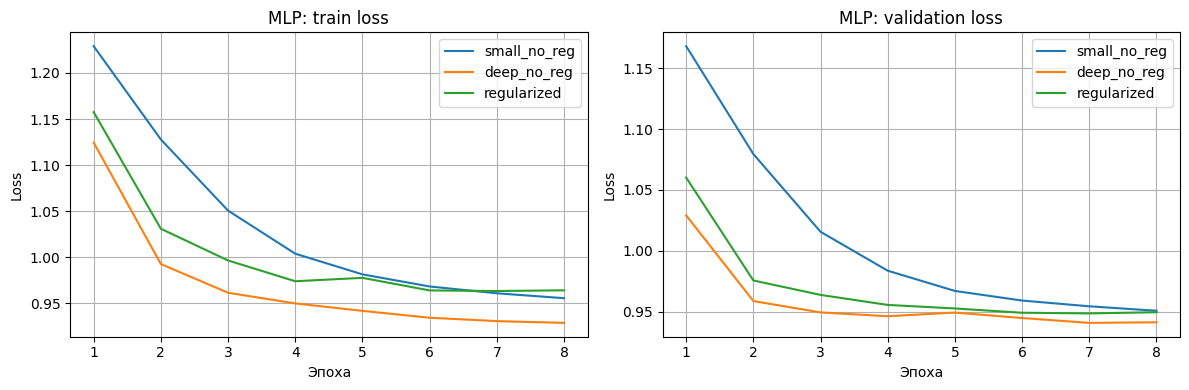

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, history in mlp_histories.items():
    # Постройте train loss и validation loss для каждой конфигурации
    axes[0].plot(history['epoch'], history['train_loss'], label=name)
    axes[1].plot(history['epoch'], history['loss'], label=name)

axes[0].set_title("MLP: train loss")
axes[1].set_title("MLP: validation loss")

for ax in axes:
    ax.set_xlabel("Эпоха")
    ax.set_ylabel("Loss")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

### Вывод по эксперименту 1

#### Модели

Проведено обучение трёх MLP-моделей, различающихся набором гиперпараметров.
По результатам оценки на валидационной выборке по ключевой метрике PR-AUC наилучший результат показала конфигурация `small_no_reg`: 
- 1 скрытый слой нейросети
- нет регуляризации: нет штрафа за большие веса, нет dropout-механизма

Модель, показавшая наилучший результат, является наиболее простой по сравнению с другими рассмотренными. Несмотря на простоту, она наилучшим образом уловила закономерности в данных и показала лучшую целевую метрику PR-AUC на валидации. Из графиков обучения и проверки качества видно, что loss на train и validate монотонно убывает, что свидетельствует об отсутствии переобучения.

Добавление регуляризации к более сложным моделям (с большим количеством и большей размерностью скрытых слоёв) не добавило качества, отличия по loss минимальны.

#### Данные

Рассмотренные числовые признаки не позволяют определить смысловое наполнение отзыва и плохо учитывают тональность. Количество восклицательных знаков, caps lock и количество эмодзи говорят только о степени эмоциональности отзыва, но не позволяют сделать выводы о позитивности/негативности.

#### Рекомендации
- Для улучшения качества моделей необходим учет семантики отзывов. Помимо количественного присутствия различных символов необходимо учитывать и смысл написанных слов


## 5. Эксперимент 2 — Embedding + mean pooling + MLP

### 5.1. Готовая подготовка текста

три специальных элемента логики:

- `PAD_IDX` — индекс для добивки коротких текстов до одной длины.
- `UNK_IDX` — индекс для редких или неизвестных слов.
- `text_to_indices` — функция, которая превращает текст в список индексов словаря.


In [24]:
TOKEN_RE = re.compile(r"[а-яёa-z0-9]+", flags=re.IGNORECASE)
PAD_IDX = 0
UNK_IDX = 1


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(str(text).lower())


def build_vocab(texts, min_freq: int = 2, max_size: int = 20_000) -> dict:
    """Подготовка словаря
    
    1. Токенизация (очистка от малоинформативных символов, приведение к единому регистру)
    2. Оставляем только топ 20к наиболее часто встречающихся слов 
    """
    counter = Counter()
    for text in texts:
        counter.update(tokenize(text))

    vocab = {"<PAD>": PAD_IDX, "<UNK>": UNK_IDX}
    for token, count in counter.most_common(max_size - len(vocab)):
        if count >= min_freq:
            vocab[token] = len(vocab)

    return vocab


def text_to_indices(text: str, vocab: dict) -> list[int]:
    """
    Преобразование текста в список индексов токенов.
    Если слову не соответствует токен из словаря, то производится замена на UNK_IDX
    """
    return [vocab.get(token, UNK_IDX) for token in tokenize(text)]


vocab = build_vocab(train_df["text"], min_freq=2, max_size=20_000)
print(f"Размер словаря: {len(vocab)}")
print("Первые элементы словаря:", list(vocab.items())[:10])

Размер словаря: 18823
Первые элементы словаря: [('<PAD>', 0), ('<UNK>', 1), ('и', 2), ('в', 3), ('на', 4), ('не', 5), ('очень', 6), ('с', 7), ('что', 8), ('все', 9)]


### 5.2. Dataset и пэддинг

In [26]:
class ReviewsTextDataset(Dataset):
    def __init__(self, texts, target, vocab: dict, max_length: int = 120):
        self.texts = list(texts)
        self.target = np.array(target, dtype=np.float32)
        self.vocab = vocab
        self.max_length = max_length

    def __len__(self):
        # Верните количество текстов
        return len(self.texts)

    def __getitem__(self, idx):
        """Получить список токенов по индексу текста"""
        # преобразование текста в список токенов из словаря
        ids = text_to_indices(self.texts[idx], self.vocab) 

        # обрезать список по порогу длины max_length
        ids = ids[:self.max_length] if len(ids) > self.max_length else ids

        # Если последовательность короче max_length, добавьте PAD_IDX
        if len(ids) < self.max_length:
            ids = ids + [PAD_IDX] * (self.max_length - len(ids))

        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(self.target[idx], dtype=torch.float32),
        )



In [27]:
MAX_LENGTH = 120

text_loaders = {
    "train": DataLoader(
        ReviewsTextDataset(texts=train_df['text'], target=train_df['target'], vocab=vocab),
        batch_size=BATCH_SIZE,
        shuffle=True,
    ),
    "val": DataLoader(
        ReviewsTextDataset(texts=val_df['text'], target=val_df['target'], vocab=vocab),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
    "test": DataLoader(
        ReviewsTextDataset(texts=test_df['text'], target=test_df['target'], vocab=vocab),
        batch_size=BATCH_SIZE,
        shuffle=False,
    ),
}

ids_batch, text_target_batch = next(iter(text_loaders["train"]))
print("ids_batch:", ids_batch.shape, ids_batch.dtype)
print("target_batch:", text_target_batch.shape, text_target_batch.dtype)

ids_batch: torch.Size([128, 120]) torch.int64
target_batch: torch.Size([128]) torch.float32


### 5.3. Модель с Embedding и mean pooling


In [28]:
class EmbeddingMLP(nn.Module):
    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int = 64,
        hidden_dim: int = 64,
        dropout: float = 0.3,
        pad_idx: int = PAD_IDX,
    ):
        super().__init__()
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=embedding_dim,
            padding_idx=pad_idx,
        )
        self.classifier = nn.Sequential(
            nn.Linear(embedding_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1),
        )
        self.pad_idx = pad_idx

    def forward(self, input_ids):
        # 1. эмбеддинги
        embeddings = self.embedding(input_ids)

        # 2. PAD-токены нужны только для выравнивания длин
        # Маска помогает не учитывать их при усреднении
        mask = (input_ids != self.pad_idx).unsqueeze(-1)
        
        masked_embeddings = embeddings * mask
        lengths = mask.sum(dim=1).clamp(min=1)

        # 3. Выполните mean pooling и передайте результат в MLP
        pooled = masked_embeddings.sum(dim=1) / lengths
        logits = self.classifier(pooled)
        return logits

### 5.4. Обучение, оценка и сохранение

In [29]:
text_config = {
    "embedding_dim": 64,
    "hidden_dim": 64,
    "dropout": 0.3,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "epochs": 8,
}

set_seed(RANDOM_STATE)

text_model = EmbeddingMLP(
    vocab_size=len(vocab),
    embedding_dim=text_config["embedding_dim"],
    hidden_dim=text_config["hidden_dim"],
    dropout=text_config["dropout"],
)

text_model, text_history = run_experiment(text_model, text_loaders, text_config)
text_test_metrics, y_true_text_test, y_prob_text_test = evaluate(
    text_model,
    text_loaders["test"],
    criterion,
    device,
)

text_model_results = pd.DataFrame({
    "name": 'text_model',
    "best_val_pr_auc": text_history["pr_auc"].max(),
    **text_test_metrics,
}, index=[0])
display(text_model_results.head())

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
0,text_model,0.596523,0.621177,0.945272,0.51341,0.832298,0.635071,0.912797,0.640502


In [30]:
results = pd.concat([mlp_results, text_model_results], ignore_index=True).sort_values(by='best_val_pr_auc', ascending=False)

results.head()

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
3,text_model,0.596523,0.621177,0.945272,0.513410,0.832298,0.635071,0.912797,0.640502
0,deep_no_reg,0.388938,0.381900,0.809528,0.265854,0.677019,0.381786,0.800113,0.972456
1,small_no_reg,0.385513,0.380394,0.801602,0.237996,0.708075,0.356250,0.766704,0.995805
2,regularized,0.373972,0.377170,0.804176,0.248307,0.683230,0.364238,0.782559,0.980554


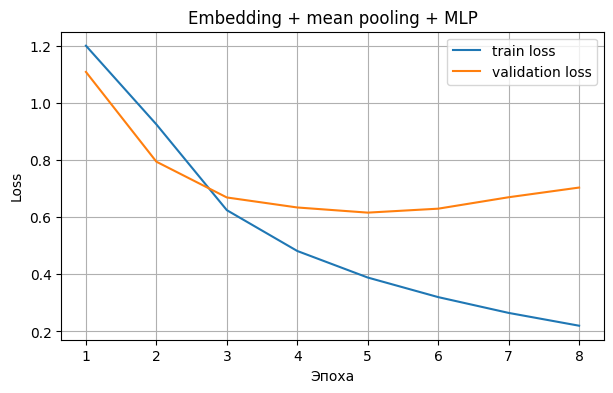

In [31]:
plt.figure(figsize=(7, 4))

# Постройте train loss и validation loss для текстовой модели
plt.plot(text_history['epoch'], text_history['train_loss'], label="train loss")
plt.plot(text_history['epoch'], text_history['loss'], label="validation loss")

plt.title("Embedding + mean pooling + MLP")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()
plt.show()

In [32]:
best_text_path = MODELS_DIR / "best_embedding_mlp.pt"

# Сохраните веса текстовой модели через state_dict
torch.save(text_model.state_dict(), best_text_path)

print(f"state_dict текстовой модели сохранён в: {best_text_path}")

state_dict текстовой модели сохранён в: models/best_embedding_mlp.pt


<font color='blue'><b>Комментарий ревьюера: </b></font> ✔️

<font color='green'>

- Текстовая модель обучена через тот же <code>run_experiment</code>, лучшая эпоха выбрана по val PR-AUC, тестовые метрики посчитаны, веса сохранены через <code>state_dict</code>.
</font>

### 5.5. Анализ ошибок текстовой модели

In [33]:
error_analysis = test_df[["text", "target", "review_len_words"]].copy()
error_analysis["prob_negative"] = y_prob_text_test
error_analysis["prediction"] = (error_analysis["prob_negative"] >= 0.5).astype(int)

In [34]:

# Найдите false positive: модель считает отзыв негативным, но target = 0
# Полезно отсортировать такие примеры по prob_negative по убыванию
false_positive = error_analysis[
    (error_analysis["prediction"] == 1) & (error_analysis["target"] == 0)
].sort_values(by='prob_negative', ascending=False)

# Найдите false negative: модель пропускает негативный отзыв
# Полезно отсортировать такие примеры по prob_negative по возрастанию
false_negative = error_analysis[
    (error_analysis["prediction"] == 0) & (error_analysis["target"] == 1)
].sort_values(by='prob_negative', ascending=False)


print("False positive: модель считает отзыв негативным, но target = 0")
display(false_positive.head())

print("False negative: модель пропускает негативный отзыв")
display(false_negative.head())

False positive: модель считает отзыв негативным, но target = 0


,text,target,review_len_words,prob_negative,prediction
10024,"Контора с понятиями! Встречают как надо,обещания выполняют. Справки не нужны,можно даже ВИЧ инфицированным работать. Главное при отлове птиц не повредить кожный покров. Чтоб не попасть в просак",0,29,0.998306,1
1235,"Грамотный специалист, объяснит, поможет.",0,4,0.997052,1
4011,"Медленно, печально,на кассе такое ощущение что просто тянут время.\nОдин сотрудник в отделе декора,которому просто не разорваться",0,19,0.995921,1
6007,"Заказ собирается не правильно, не докладывают вместо 2 кладут 1. Сколько раз не давали трубочки к коктейлем. Я много раз жаловалась администратору. Её ответ мы проведём беседу, видимо до сих пор проводят. Игры дороги...",0,38,0.995130,1
7875,"Тц уже не такое популярное как когда то, большинство ларьков пустует, возле одного из туалетов запах не целую галлерею, это ужас. Притом это уже не первый месяц так. Ну в принципе сходить можно",0,33,0.994833,1


False negative: модель пропускает негативный отзыв


,text,target,review_len_words,prob_negative,prediction
4857,"Обслуживание на нуле: продавцы со своим товаром совершенно не знакомы, помощи оказать не могут. Всё приходится делать самому и найти товар и узнать о его качестве. Хорошо ещё хоть согласились с верхней полки помочь ...",1,35,0.491985,0
4429,"Думаю не нужны длинные отзывы— просто не вкусно. То есть от слова совсем. Из 6 блюд которые брали на двоих более менее был овощной салат. Причина— очень дешевые продукты (окрошка с колбасой, которую вы сами никогда ...",1,63,0.489272,0
1036,"Если придёте сюда компанией из 5 человек, из которых только двое курят кальян - вам скажут заказывайте минимум 2 кальяна одновременно, за 2.200\n\nНа вопрос почему нельзя 1 кальян взять, сказали сейчас везде такие пр...",1,48,0.470519,0
1748,"У администрации сети этих кофеен есть уморительная практика - блокировать в своем приложении пользователей, которые жалуются на сбои в его работе)) Красавцы, конечно, уровень менеджмента - боги!🤣🤣🤣",1,25,0.458285,0
7069,"Замечательный магазин, ремонт и прочее. Живу рядом, захожу почти каждый день. НО, очень ужасное обслуживание. В час пик работает 2 кассы, кассиры еле живые. Директор на замечания не реагирует. Похоже с ценниками бед...",1,79,0.445629,0


**Анализ найденных ошибок**

Ошибки FP:
- негативная частица `не` подталкивает модель к негативной классификации, хотя отзыв по смыслу положительный
- модель не различает полутона: отзыв скорее нейтрально-положительный, но модель его считает отрицательным из-за подмеченных негативных факторов
- в коротких отзывах с редкими словами все слова могут быть заменены на UNK-токен, модель некорректно классифицирует такой отзыв

Ошибки FN:
- явно негативный отзыв без частиц `не` модель не воспринимает как негативный 
- отзыв с негативной пользовательской историей, в которой нет явных негативных слов, приводит к ошибкам
- негативные слова `тонут` при сторителлинге
- модель не ловит иронию 

Разметка данных:
- есть ошибки в разметке данных (особенность постановки задачи) — отзыв явно негативный, но принятая за истину классификация не соответствует содержанию отзыва

In [38]:
results

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
3,text_model,0.596523,0.621177,0.945272,0.513410,0.832298,0.635071,0.912797,0.640502
0,small_no_reg,0.392304,0.355323,0.779265,0.182236,0.739130,0.292383,0.673839,1.114461
1,deep_no_reg,0.390834,0.383136,0.809168,0.260465,0.695652,0.379019,0.792186,0.971555
2,regularized,0.376584,0.374966,0.802248,0.255125,0.695652,0.373333,0.787089,0.986733


### Вывод по эксперименту 2

Обучение:
- качество на validate начинает падать после 5-й эпохи, это свидетельствует о начале переобучения
- чтобы бороться с переобучением, можно либо остановить обучение раньше, либо упростить модель, либо усилить регуляризацию (на будущее возможные доработки)

Текстовая модель показывает существенно лучшие результаты по ключевым метрикам на тестовой выборке: 
- +75% по PR-AUC
- -43% loss

Анализ ошибок модели в части FP и FN показал:
- ложноположительные срабатывания происходят при наличии негативных слов и частицы. Не хватает понимания смысла последовательности слов 
- ложноотрицательные срабатывания происходят, если негативных слов и частиц нет, хотя отзыв явно негативный. Негативные частицы "теряются" при длительных отзывах и сторителлинге 
- есть ошибки в разметке данных - отзыв явно негативный, но мы считаем его положительным. Это особенность генерации таргета 

В текстовой модели использован `mean pooling`. Ограничение этого метода усреднения проявляется, когда важные для классификации слова "тонут" (усредняются) в объёмном тексте.

Текстовое представление позволяет в большей степени учитывать смысл отзывов, модель учитывает ключевые слова и семантику из значений.

## 6. Итоговое сравнение


In [35]:
results

,name,best_val_pr_auc,pr_auc,roc_auc,precision,recall,f1,accuracy,loss
3,text_model,0.596523,0.621177,0.945272,0.513410,0.832298,0.635071,0.912797,0.640502
0,deep_no_reg,0.388938,0.381900,0.809528,0.265854,0.677019,0.381786,0.800113,0.972456
1,small_no_reg,0.385513,0.380394,0.801602,0.237996,0.708075,0.356250,0.766704,0.995805
2,regularized,0.373972,0.377170,0.804176,0.248307,0.683230,0.364238,0.782559,0.980554


In [36]:
best_mpl_model_res = results[results['name'] != 'text_model'].loc[0]
text_model_results = results[results['name'] == 'text_model'].iloc[0, :]

In [37]:


final_comparison = pd.DataFrame(
    [
        {
            "Подход": "MLP на числовых признаках",
            "PR-AUC test": best_mpl_model_res['pr_auc'],
            "ROC-AUC test": best_mpl_model_res['roc_auc'],
            "Precision": best_mpl_model_res['precision'],
            "Recall": best_mpl_model_res['recall'],
            "F1": best_mpl_model_res['f1'],
            "Ограничения": "Количественные признаки текста не учитывают значения слов в отзывах",
        },
        {
            "Подход": "Embedding + pooling + MLP",
            "PR-AUC test": text_model_results['pr_auc'],
            "ROC-AUC test": text_model_results['roc_auc'],
            "Precision": text_model_results['precision'],
            "Recall": text_model_results['recall'],
            "F1": text_model_results['f1'],
            "Ограничения": "Контекст отзыва усредняется. Модель не улавливает общий смысл предложения.",
        },
    ]
)

display(final_comparison)

,Подход,PR-AUC test,ROC-AUC test,Precision,Recall,F1,Ограничения
0,MLP на числовых признаках,0.381900,0.809528,0.265854,0.677019,0.381786,Количественные признаки текста не учитывают значения слов в отзывах
1,Embedding + pooling + MLP,0.621177,0.945272,0.513410,0.832298,0.635071,Контекст отзыва усредняется. Модель не улавливает общий смысл предложения.


## Итоговые выводы

Второй подход с учетом смысла слов в отзыве показал намного лучшее качество:
- +75% по ключевой метрике PR-AUC на test
- -43% loss на test
- по остальным метрикам классификации также наблюдается существенная разница в пользу подхода `Embedding + pooling + MLP`.

Текстовая модель учла среднюю тональность отзыва: если в основном содержались негативные или позитивные слова, то модель корректно их учла при классификации. Можно сказать, что модель в некоторой степени стала учитывать усредненный смысл отзыва.

Модель чисто на количественных признаках косвенным образом учитывает эмоции отзыва (подсчет букв капсом, знаки препинания и эмодзи). Эти признаки не позволяют в большинстве случаев отделить негативные от позитивных отзывов.

Анализируя применённый `mean pooling`, стоит сказать, что эта техника усредняет общий смысл сказанного в предложении и приводит к потере смысла в длинных предложениях.

Дисбаланс классов был учтён при разделении на выборки и при подсчёте loss-функции, но мог повлиять на способность моделей увидеть достаточное количество негативных отзывов, чтобы научиться их выделять.

Разметка отзывов не всегда позволяет корректно классифицировать отзыв. Взглянув на данные, можно заметить, что в позитивные отзывы записываются пограничные оценки (3 балла), что приводит к ошибкам при интерпретации работы моделей. Шум в таргете мешает обучению и корректной оценке итогового качества. Для получения более качественного результата необходима ручная разметка таргета.

Для будущего эксперимента предлагается:
- провести ручную разметку датасета, особенно отзывов с оценкой 3. Это позволит снизить шум в таргете. 
- провести байесовскую оптимизацию гиперпараметров с помощью Optuna. Это позволит более качественно подобрать гиперпараметры и, возможно, получить лучшее качество
